# RoBERTa (roberta-base)

In [ ]:
!pip install -q transformers

In [ ]:
import copy
import itertools
import json
import time
from pathlib import Path
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from sklearn.metrics import accuracy_score, auc, classification_report, confusion_matrix, roc_curve
from torch.optim import AdamW
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm
from transformers import AutoModelForSequenceClassification, AutoTokenizer, get_linear_schedule_with_warmup
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

DRIVE_DIR = Path("/content/drive/MyDrive/NLP_project")
DRIVE_DIR.mkdir(parents=True, exist_ok=True)

DATASET_PATH = str(DRIVE_DIR / "merged_dataset(1).txt")
RESULTS_DIR = DRIVE_DIR / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODEL_SAVE_PATH = str(RESULTS_DIR / "best_roberta_model.bin")
PRE_TRAINED_MODEL_NAME = "roberta-base"

device = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = device == "cuda"
print(f"Using device: {device}")
torch.manual_seed(42)
np.random.seed(42)
if device == "cuda":
    torch.cuda.manual_seed_all(42)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using device: cuda


## Khảo sát độ dài văn bản (chọn MAX_LEN)

Tỷ lệ văn bản có độ dài <= 256 từ: 63.85%
Tỷ lệ văn bản có độ dài <= 512 từ: 92.47%
Phân vị 80: 362 từ
Phân vị 90: 466 từ
Phân vị 95: 582 từ
Phân vị 98: 742 từ
Phân vị 99: 867 từ
Phân vị 100: 7904 từ


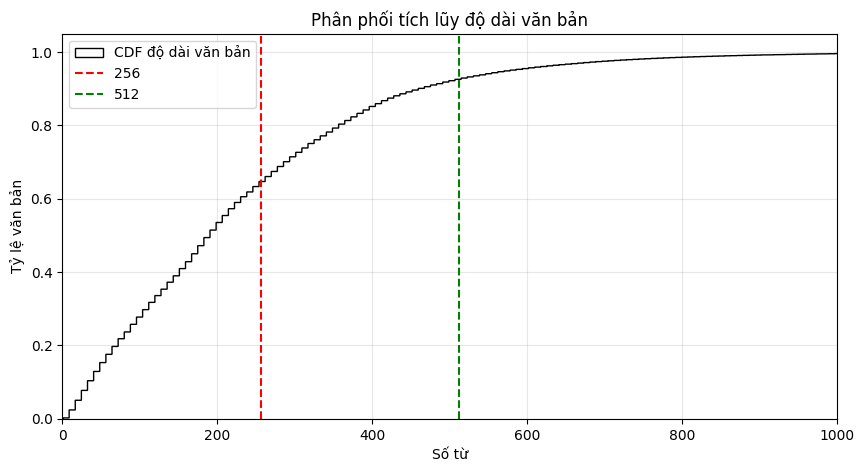

In [ ]:
df_eda = pd.read_csv(DATASET_PATH)
df_eda.dropna(subset=["text"], inplace=True)
sequence_lengths = [len(text.split()) for text in df_eda["text"].astype(str).values]

for max_len in (256, 512):
    coverage = np.mean(np.array(sequence_lengths) <= max_len) * 100
    print(f"Tỷ lệ văn bản có độ dài <= {max_len} từ: {coverage:.2f}%")
for p in [80, 90, 95, 98, 99, 100]:
    print(f"Phân vị {p}: {int(np.percentile(sequence_lengths, p))} từ")

plt.figure(figsize=(10, 5))
plt.hist(sequence_lengths, bins=1000, density=True, cumulative=True, histtype="step", color="k", label="CDF độ dài văn bản")
plt.axvline(256, color="red", linestyle="--", label="256")
plt.axvline(512, color="green", linestyle="--", label="512")
plt.xlim(0, 1000); plt.xlabel("Số từ"); plt.ylabel("Tỷ lệ văn bản"); plt.grid(alpha=0.3); plt.legend()
plt.title("Phân phối tích lũy độ dài văn bản")
plt.show()
del df_eda, sequence_lengths

## Nạp dữ liệu và chia theo chủ đề

In [ ]:
df = pd.read_csv(DATASET_PATH)
df = df.sample(frac=1, random_state=42).reset_index(drop=True)
df.dropna(subset=["text"], inplace=True)
df["text"] = df["text"].astype(str)

train_sources = [
    "HC3_reddit_eli5",
    "HC3_finance",
    "DAIGT_v2_Distance learning",
    "DAIGT_v2_Seeking multiple opinions",
    "HC3_open_qa",
]
val_sources = [
    "DAIGT_v2_Car-free cities",
    "DAIGT_v2_Does the electoral college work?",
    "DAIGT_v2_Facial action coding system",
    "DAIGT_v2_Mandatory extracurricular activities",
    "DAIGT_v2_Summer projects",
    "HC3_medicine",
    "DAIGT_v2_Driverless cars",
    "DAIGT_v2_Exploring Venus",
]
test_sources = [
    "DAIGT_v2_Cell phones at school",
    "DAIGT_v2_Grades for extracurricular activities",
    "DAIGT_v2_Community service",
    'DAIGT_v2_"A Cowboy Who Rode the Waves"',
    "DAIGT_v2_The Face on Mars",
    "HC3_wiki_csai",
    "DAIGT_v2_Phones and driving",
]

missing = set(train_sources + val_sources + test_sources) - set(df["source"].unique())
assert not missing, f"Không tìm thấy các nguồn: {missing}"

train_df = df[df["source"].isin(train_sources)]
val_df = df[df["source"].isin(val_sources)]
test_df = df[df["source"].isin(test_sources)]

X_train, y_train = train_df["text"].values, train_df["label"].values
X_val, y_val = val_df["text"].values, val_df["label"].values
X_test, y_test = test_df["text"].values, test_df["label"].values

print(f"Tổng số mẫu:  {len(df)}")
print(f"Tập train:    {len(X_train)} ({len(X_train) / len(df):.1%})")
print(f"Tập val:      {len(X_val)} ({len(X_val) / len(df):.1%})")
print(f"Tập test:     {len(X_test)} ({len(X_test) / len(df):.1%})")

Tổng số mẫu:  124195
Tập train:    85897 (69.2%)
Tập val:      24987 (20.1%)
Tập test:     13311 (10.7%)


## Tokenizer, Dataset và DataLoader

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(PRE_TRAINED_MODEL_NAME)
MAX_LEN = 256
print(f"MAX_LEN = {MAX_LEN}")

class AITextDataset(Dataset):
    def __init__(self, texts, labels):
        self.texts, self.labels = texts, labels
    def __len__(self):
        return len(self.texts)
    def __getitem__(self, item):
        return str(self.texts[item]), int(self.labels[item])

def collate_fn(batch):
    texts, labels = zip(*batch)
    encoding = tokenizer(list(texts), truncation=True, max_length=MAX_LEN, padding=True, return_tensors="pt")
    encoding["labels"] = torch.tensor(labels, dtype=torch.long)
    return encoding

class BucketBatchSampler:
    """Gom các văn bản có độ dài gần nhau vào cùng batch để giảm padding (nhanh hơn, kết quả tương đương)."""
    def __init__(self, lengths, batch_size, shuffle, bucket_size=100):
        self.lengths, self.batch_size, self.shuffle = np.asarray(lengths), batch_size, shuffle
        self.bucket_size = bucket_size * batch_size if shuffle else len(lengths)   # đánh giá: sắp xếp toàn bộ
    def __iter__(self):
        n = len(self.lengths)
        order = np.random.permutation(n) if self.shuffle else np.arange(n)
        batches = []
        for i in range(0, n, self.bucket_size):
            bucket = order[i:i + self.bucket_size]
            bucket = bucket[np.argsort(self.lengths[bucket], kind="stable")]
            batches += [bucket[j:j + self.batch_size].tolist() for j in range(0, len(bucket), self.batch_size)]
        if self.shuffle:
            random.shuffle(batches)
        return iter(batches)
    def __len__(self):
        return (len(self.lengths) + self.batch_size - 1) // self.batch_size

def create_data_loader(texts, labels, batch_size, shuffle=False):
    sampler = BucketBatchSampler([len(t) for t in texts], batch_size, shuffle)
    return DataLoader(AITextDataset(texts, labels), batch_sampler=sampler, collate_fn=collate_fn)

MAX_LEN = 256


## Hàm huấn luyện và đánh giá

In [ ]:
def train_epoch(model, data_loader, optimizer, scheduler, scaler):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for batch in tqdm(data_loader, desc="Training", leave=False):
        batch = {k: v.to(device) for k, v in batch.items()}
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            outputs = model(**batch)
        scaler.scale(outputs.loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        total_loss += outputs.loss.item()
        correct += (outputs.logits.argmax(dim=-1) == batch["labels"]).sum().item()
        total += batch["labels"].size(0)
    return total_loss / len(data_loader), correct / total

@torch.no_grad()
def eval_model(model, data_loader):
    model.eval()
    total_loss, preds, probs, labels = 0.0, [], [], []
    for batch in tqdm(data_loader, desc="Evaluating", leave=False):
        batch = {k: v.to(device) for k, v in batch.items()}
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            outputs = model(**batch)
        total_loss += outputs.loss.item()
        p = torch.softmax(outputs.logits.float(), dim=-1)
        preds.extend(p.argmax(dim=-1).cpu().tolist())
        probs.extend(p[:, 1].cpu().tolist())
        labels.extend(batch["labels"].cpu().tolist())
    return total_loss / len(data_loader), accuracy_score(labels, preds), np.array(preds), np.array(probs), np.array(labels)

## Tìm kiếm siêu tham số

In [ ]:

param_grid = {
    "learning_rate": [2e-5],
    "batch_size": [16],
    "epochs": [2],
}
all_params = [dict(zip(param_grid.keys(), v)) for v in itertools.product(*param_grid.values())]

best_val_accuracy, best_params, best_history, results_log = 0.0, {}, None, []
grid_start_time = time.time()

for i, params in enumerate(all_params):
    print(f"\n--- Config {i + 1}/{len(all_params)}: {params} ---")
    model = AutoModelForSequenceClassification.from_pretrained(PRE_TRAINED_MODEL_NAME, num_labels=2).to(device)
    optimizer = AdamW(model.parameters(), lr=params["learning_rate"])
    train_loader = create_data_loader(X_train, y_train, params["batch_size"], shuffle=True)
    val_loader = create_data_loader(X_val, y_val, params["batch_size"] * 4)
    scheduler = get_linear_schedule_with_warmup(optimizer, 0, len(train_loader) * params["epochs"])
    scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)

    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    config_has_best = False
    start = time.time()
    for epoch in range(params["epochs"]):
        train_loss, train_acc = train_epoch(model, train_loader, optimizer, scheduler, scaler)
        eval_start = time.time()
        val_loss, val_acc, _, _, _ = eval_model(model, val_loader)
        inference_duration = time.time() - eval_start
        history["train_loss"].append(train_loss); history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss); history["val_acc"].append(val_acc)
        print(f"  Epoch {epoch + 1}/{params['epochs']} | Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} "
              f"| Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}")

        if val_acc > best_val_accuracy:
            best_val_accuracy, best_params, config_has_best = val_acc, params, True
            torch.save(model.state_dict(), MODEL_SAVE_PATH)
            print("  -> Val accuracy tốt nhất, đã lưu mô hình.")
    training_time = time.time() - start

    if config_has_best:
        best_history = history
    results_log.append({"config": str(params), "val_accuracy": max(history["val_acc"]),
                        "training_time_s": training_time, "inference_time_s": inference_duration})
    del model, optimizer, scheduler

grid_time = time.time() - grid_start_time
print(f"\nGrid search hoàn thành sau {grid_time:.2f} giây.")
print(f"Cấu hình tốt nhất: {best_params} | Val Acc: {best_val_accuracy:.4f}")
pd.DataFrame(results_log).sort_values("val_accuracy", ascending=False)


--- Config 1/1: {'learning_rate': 2e-05, 'batch_size': 16, 'epochs': 2} ---


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/tmp/ipykernel_17685/4230961990.py:18: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScal

Training:   0%|          | 0/5369 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/391 [00:00<?, ?it/s]

  Epoch 1/2 | Train Loss: 0.0266 Acc: 0.9938 | Val Loss: 0.3352 Acc: 0.9361
  -> Val accuracy tốt nhất, đã lưu mô hình.


Training:   0%|          | 0/5369 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/391 [00:00<?, ?it/s]

  Epoch 2/2 | Train Loss: 0.0043 Acc: 0.9992 | Val Loss: 1.9141 Acc: 0.7620

Grid search hoàn thành sau 2301.91 giây.
Cấu hình tốt nhất: {'learning_rate': 2e-05, 'batch_size': 16, 'epochs': 2} | Val Acc: 0.9361


,config,val_accuracy,training_time_s,inference_time_s
0,"{'learning_rate': 2e-05, 'batch_size': 16, 'ep...",0.936087,2300.414412,125.621916


## Đánh giá trên tập test

In [ ]:
final_model = AutoModelForSequenceClassification.from_pretrained(PRE_TRAINED_MODEL_NAME, num_labels=2).to(device)
final_model.load_state_dict(torch.load(MODEL_SAVE_PATH, map_location=device))
test_loader = create_data_loader(X_test, y_test, best_params["batch_size"] * 4)

start = time.time()
_, test_acc, y_test_pred, y_test_score, y_test = eval_model(final_model, test_loader)
infer_time = time.time() - start
print(f"Suy luận trên {len(y_test)} mẫu test mất {infer_time:.2f} giây.")
print(f"\nTest accuracy: {test_acc:.4f}")
print("\nClassification Report (Test Set):")
print(classification_report(y_test, y_test_pred, target_names=["Human", "AI"]))

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Evaluating:   0%|          | 0/208 [00:00<?, ?it/s]

Suy luận trên 13311 mẫu test mất 64.18 giây.

Test accuracy: 0.8840

Classification Report (Test Set):
              precision    recall  f1-score   support

       Human       1.00      0.84      0.91      9717
          AI       0.70      1.00      0.82      3594

    accuracy                           0.88     13311
   macro avg       0.85      0.92      0.87     13311
weighted avg       0.92      0.88      0.89     13311



In [ ]:
def save_results(name, file, y_true, y_pred, y_score, train_acc, val_acc, train_time, infer_time, best_params, history=None):
    """Lưu kết quả để notebook so sánh đọc lại."""
    fpr, tpr, _ = roc_curve(y_true, y_score)
    result = {
        "model": name,
        "best_params": str(best_params),
        "train_acc": float(train_acc),
        "val_acc": float(val_acc),
        "test_acc": float(accuracy_score(y_true, y_pred)),
        "roc_auc": float(auc(fpr, tpr)),
        "train_time_s": float(train_time),
        "infer_time_s": float(infer_time),
        "report": classification_report(y_true, y_pred, target_names=["Human", "AI"], output_dict=True),
        "confusion_matrix": confusion_matrix(y_true, y_pred).tolist(),
        "fpr": fpr.tolist(),
        "tpr": tpr.tolist(),
        "history": history,
    }
    with open(RESULTS_DIR / file, "w", encoding="utf-8") as f:
        json.dump(result, f, ensure_ascii=False)
    print(f"Đã lưu kết quả: {RESULTS_DIR / file}")

best_epoch = int(np.argmax(best_history["val_acc"]))
save_results("RoBERTa", "results_roberta.json", y_test, y_test_pred, y_test_score,
             best_history["train_acc"][best_epoch], best_val_accuracy, grid_time, infer_time,
             best_params, history=best_history)

Đã lưu kết quả: /content/drive/MyDrive/NLP_project/results/results_roberta.json


## Biểu đồ

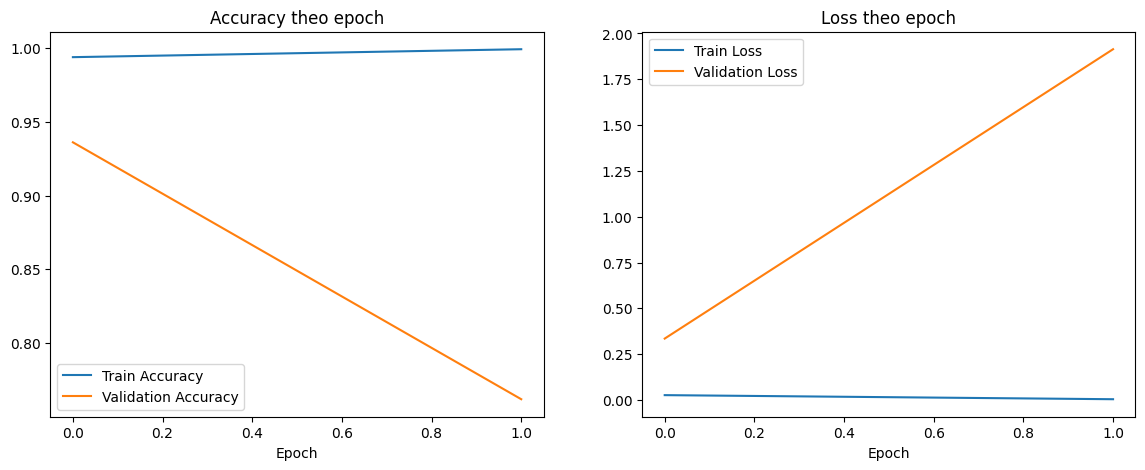

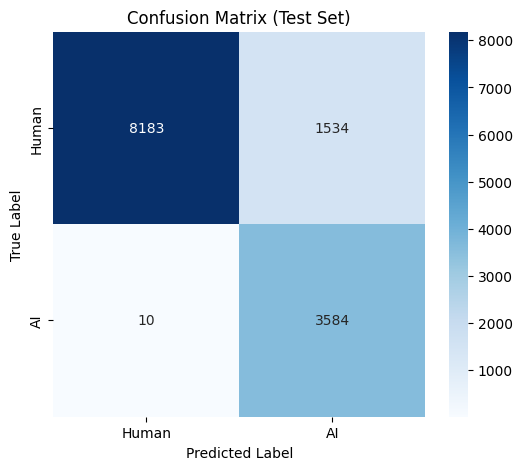

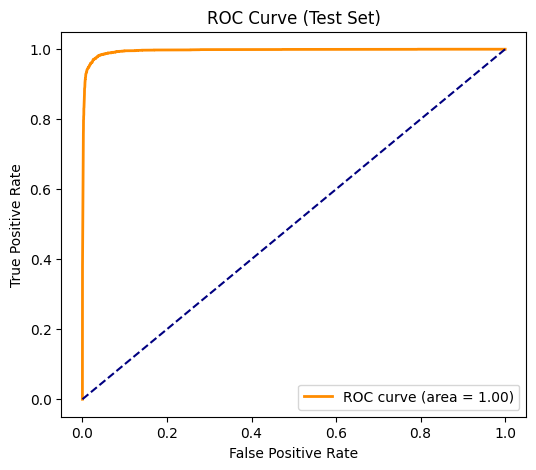

In [ ]:
history = best_history

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(history["train_acc"], label="Train Accuracy"); ax1.plot(history["val_acc"], label="Validation Accuracy")
ax1.set_title("Accuracy theo epoch"); ax1.set_xlabel("Epoch"); ax1.legend()
ax2.plot(history["train_loss"], label="Train Loss"); ax2.plot(history["val_loss"], label="Validation Loss")
ax2.set_title("Loss theo epoch"); ax2.set_xlabel("Epoch"); ax2.legend()
plt.show()

cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Human", "AI"], yticklabels=["Human", "AI"])
plt.xlabel("Predicted Label"); plt.ylabel("True Label"); plt.title("Confusion Matrix (Test Set)")
plt.show()

fpr, tpr, _ = roc_curve(y_test, y_test_score)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC curve (area = {auc(fpr, tpr):.2f})")
plt.plot([0, 1], [0, 1], color="navy", linestyle="--")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.title("ROC Curve (Test Set)")
plt.legend(loc="lower right"); plt.show()